# Lightpath: cloud task placement on network graphs

Servers are graph nodes and link latencies are edge weights. This notebook walks through the pipeline on the project's datasets: graph algorithms (MST, Dijkstra, Bellman-Ford, Floyd–Warshall, Johnson), knapsack DP, greedy placement with local search, and the exact MILP used to measure the optimality gap.

*Built by Naman Singla and Mohak Gupta, guided by Dr. Monday Jubrin Abdullahi.*

In [1]:
import sys, json, time
sys.path.insert(0, '..')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from cloudplace.data import build_instance
from cloudplace.algorithms import (prim, kruskal, dijkstra, bellman_ford, apsp,
    floyd_warshall_numpy, johnson, knapsack_01, NegativeCycleError)
from cloudplace.model import transfer_cost_graph
from cloudplace.solver import solve, SolveConfig
pd.set_option('display.width', 140)

## 1. The Woxsen University campus network
Sites and their west-to-east arrangement come from the official campus map.

In [2]:
w = build_instance('woxsen', seed=7)
print(w.summary())
pd.DataFrame([{'site': a['name'], 'tier': a['tier'], 'cpu': a['cpu']} for a in w.graph.nodes]).head(12)

{'name': 'woxsen', 'nodes': 23, 'links': 29, 'servers': 13, 'services': 8, 'tasks': 12, 'density': 0.1146, 'cpu_capacity': 288.0, 'mem_capacity': 1392.0, 'cpu_demand_min': 50, 'cpu_load_min': 0.174, 'connected': True}


,site,tier,cpu
0,Main Entrance (ISP uplink),router,0
1,Parking,router,0
2,Amphitheatre,router,0
3,Academic Block (Data Centre A),core,64
4,Bloomberg Finance Lab,edge,8
5,AI & Robotics Studio,regional,32
6,Admin Block / Gateway (Data Centre B),core,64
7,Rise Café,router,0
8,Trade Tower,regional,24
9,Central Library (Vithal Gandhi Centre),regional,24


## 2. Backbone: Prim and Kruskal agree (cut property)

In [3]:
for heap in ['binary', 'fibonacci', 'pairing', 'lazy']:
    r = prim(w.graph, heap=heap)
    print(f'Prim ({heap:9s}) weight = {r.total_weight:.4f} ms, edges = {len(r.edges)}')
k = kruskal(w.graph)
print(f'Kruskal            weight = {k.total_weight:.4f} ms, edges = {len(k.edges)}')

Prim (binary   ) weight = 1.6497 ms, edges = 22
Prim (fibonacci) weight = 1.6497 ms, edges = 22
Prim (pairing  ) weight = 1.6497 ms, edges = 22
Prim (lazy     ) weight = 1.6497 ms, edges = 22
Kruskal            weight = 1.6497 ms, edges = 22


## 3. Shortest paths from the Main Entrance (Dijkstra)

In [4]:
names = [a['name'] for a in w.graph.nodes]
d = dijkstra(w.graph, 0)
pd.DataFrame({'site': names, 'latency_ms': np.round(d.dist, 4), 'path': [' > '.join(names[x].split(' (')[0] for x in d.path_to(t)) for t in range(len(names))]}).sort_values('latency_ms').tail(6)

,site,latency_ms,path
14,Oval Dining Hall,0.3185,Main Entrance > Admin Block / Gateway > Academ...
12,Care & Cure (Medical Facility),0.3185,Main Entrance > Admin Block / Gateway > Academ...
21,Student Hostel C,0.3277,Main Entrance > Admin Block / Gateway > Trade ...
18,ICC Cricket Ground,0.3286,Main Entrance > Admin Block / Gateway > Trade ...
22,Student Hostel D,0.3982,Main Entrance > Admin Block / Gateway > Trade ...
17,Swimming Pool & Blue Embers,0.4490,Main Entrance > Admin Block / Gateway > Academ...


## 4. Negative transfer costs: why Bellman-Ford and Johnson
Transfer cost is c(u→v) = base + per_ms·latency + φ(u) − φ(v). The site price levels φ create negative arcs, but they cancel around every cycle, so no negative cycle can exist.

In [5]:
india = build_instance('india', seed=7)
tg = transfer_cost_graph(india.graph)
neg = sum(1 for e in tg.edges() if e.cost < 0)
print('directed arcs:', tg.m, ' negative arcs:', neg)
try:
    dijkstra(tg, 0, 'cost')
except ValueError as e:
    print('Dijkstra refuses:', str(e)[:80], '...')
bf = bellman_ford(tg, 0, 'cost'); jn = johnson(tg, 'cost')
print('Bellman-Ford and Johnson agree:', np.allclose(bf.dist, jn.dist[0]))

directed arcs: 88  negative arcs: 24
Dijkstra refuses: Dijkstra requires non-negative weights (edge 8->20 = -0.004952); use bellman_for ...
Bellman-Ford and Johnson agree: True


## 5. All-pairs: the automatic choice

In [6]:
for name in ['india', 'nigeria', 'er-100']:
    inst = build_instance({'er-100': 'erdos_renyi'}.get(name, name), n=100, seed=7, p=0.05)
    t = time.perf_counter(); r = apsp(inst.graph); ms = (time.perf_counter() - t) * 1e3
    print(f'{name:8s} n={inst.graph.n:3d} density={inst.graph.density():.3f} -> {r.algorithm:24s} {ms:7.2f} ms')

india    n= 25 density=0.147 -> repeated_dijkstra[binary]    1.65 ms
nigeria  n= 24 density=0.170 -> repeated_dijkstra[binary]    1.47 ms
er-100   n=100 density=0.071 -> repeated_dijkstra[binary]   41.14 ms


## 6. Knapsack DP: choosing servers within a budget

In [7]:
vals, wts = [60, 100, 120, 80, 30], [10, 20, 30, 15, 5]
r = knapsack_01(vals, wts, 50)
print('chosen items', r.chosen, 'value', r.value, 'weight', r.weight)

chosen items [0, 1, 3, 4] value 270 weight 50


## 7. Full placement on India and Nigeria

In [8]:
rows = []
for region in ['india', 'nigeria']:
    inst = build_instance(region, seed=7)
    out = solve(inst, SolveConfig())
    for s in out['strategies']:
        rows.append({'region': region, 'strategy': s['name'], 'mean_ms': s['mean_ms'], 'p95_ms': s['p95_ms'], 'gap_%': s['gap_pct'], 'runtime_ms': s['runtime_ms']})
    if region == 'india':
        india_out, india_inst = out, inst
pd.DataFrame(rows).pivot(index='strategy', columns='region', values='mean_ms').sort_values('india')

region,india,nigeria
strategy,,
demand_first+ls,2.372,1.012
exact_milp,2.372,1.001
marginal_gain+ls,2.372,1.001
ffd_pack+ls,2.372,1.012
regret+ls,2.372,1.003
demand_first,2.473,1.253
marginal_gain,2.482,1.105
regret,2.536,1.095
ffd_pack,2.628,1.395


In [9]:
for line in india_out['recommendations']:
    print('•', line)

• Deploy the 'demand_first+ls' placement: demand-weighted mean latency 2.372 ms (p95 8.382 ms) at $2.712/h.
• That is 70.0% lower latency than a random placement.
• Exact MILP optimum is 2.372 ms (solved in 35.527 ms); the best heuristic 'demand_first+ls' is within 0.0% of it in 3.969 ms.
• Best next dollar: add a replica of cache (-1.123 ms for $0.192/h).
• 3 server(s) run at ≥90% CPU (Pune, Kochi, Varanasi); capacity there is the binding constraint — upgrading them unlocks better placements.
• Provision the 24-link MST backbone first (56.165 ms total); it keeps every site connected with the cheapest links.
• Routing over the backbone alone would stretch latency by 1.61× on average; keep the non-tree links for request routing.


## 8. The India plan on a map

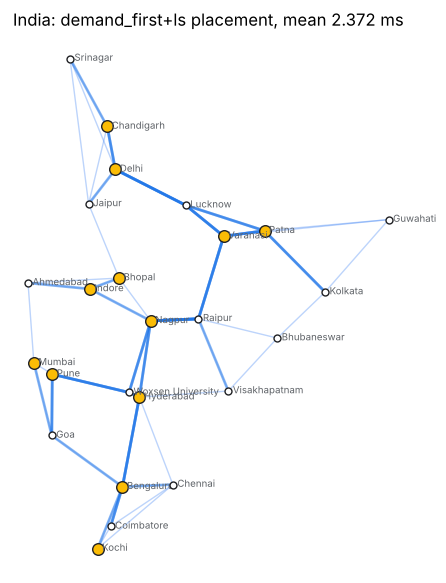

In [10]:
g = india_inst.graph; best = next(s for s in india_out['strategies'] if s['name'] == india_out['best'])
hosts = {s for S in best['replicas'].values() for s in S}
fig, ax = plt.subplots(figsize=(7, 7))
for e in g.edges():
    a, b = g.nodes[e.u], g.nodes[e.v]; ax.plot([a['x'], b['x']], [a['y'], b['y']], color='#4285F4', alpha=.35, lw=1)
for r in india_out['policy']['routes'][:40]:
    p = r['path']; ax.plot([g.nodes[i]['x'] for i in p], [g.nodes[i]['y'] for i in p], color='#1A73E8', lw=2, alpha=.5)
for i, a in enumerate(g.nodes):
    ax.scatter(a['x'], a['y'], s=70 if i in hosts else 25, c='#FBBC05' if i in hosts else 'white', edgecolors='#202124', zorder=3)
    ax.annotate(a['name'], (a['x'] + 8, a['y'] + 4), fontsize=7, color='#5F6368')
ax.invert_yaxis(); ax.set_aspect('equal'); ax.axis('off'); ax.set_title(f"India: {best['name']} placement, mean {best['mean_ms']} ms")
plt.show()

## 9. Experiment highlights
The full suite (`experiments/run_experiments.py`) writes CSVs and the report figures.

In [11]:
R = json.load(open('../experiments/results/summary.json'))['results']
q = pd.DataFrame(R['quality_size'])
q[q.gap_pct.notna()].groupby('strategy').gap_pct.agg(['mean', 'max']).round(2).sort_values('mean')

,mean,max
strategy,,
exact_milp,0.00,0.00
demand_first+ls,0.45,2.71
marginal_gain+ls,0.46,3.04
ffd_pack+ls,0.48,2.96
regret+ls,0.53,3.04
marginal_gain,8.69,26.27
regret,9.21,26.32
demand_first,16.65,43.88
ffd_pack,38.41,65.10


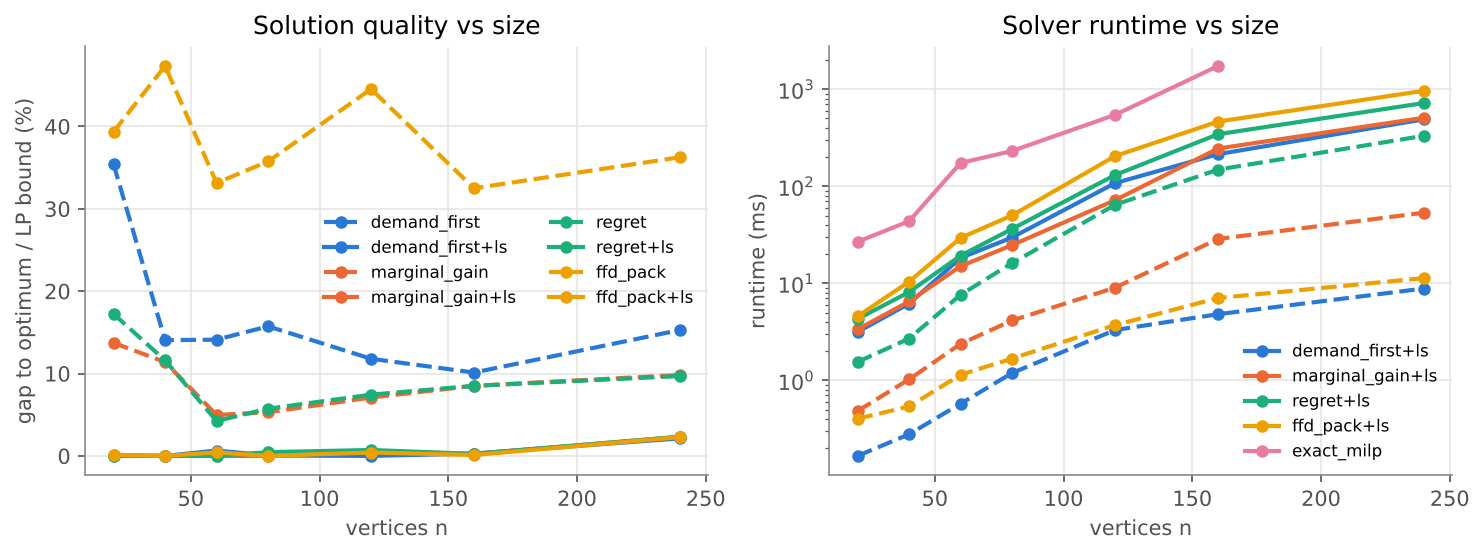

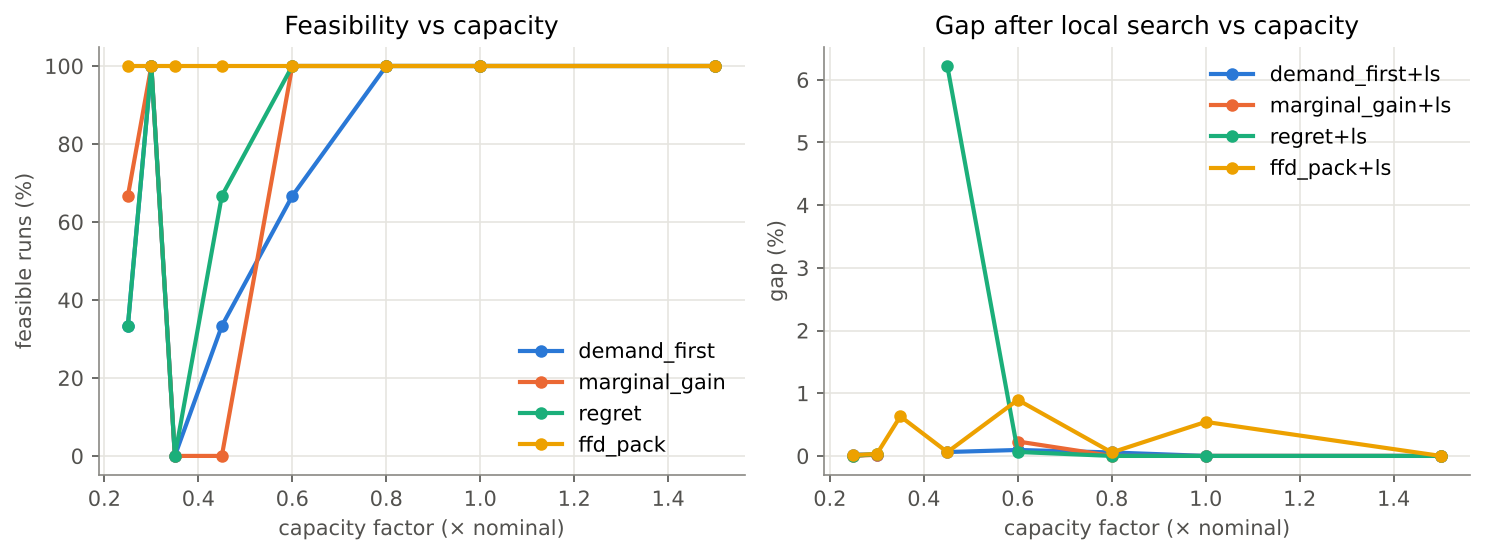

In [12]:
from IPython.display import Image, display
display(Image('../experiments/figures/e4_quality_size.png', width=900))
display(Image('../experiments/figures/e5_capacity.png', width=900))